# 01 — Data Understanding (EDA)

**CRISP-DM phase: Data Understanding.** This notebook describes the data before any model is built:
where it comes from, how much there is, what a record looks like, and what is wrong with it.
Every later design decision (three execution modes, hand labels, grouped splits) is a response to
something shown here.

The data has five layers. Each section below covers one of them.

| # | Layer | File | Size |
|---|---|---|---|
| 1 | MalSkillBench corpus (skills only, no traces) | `vendor/MalSkillBench/Dataset/Skills/` | 7,944 skills |
| 2 | Sampled skills, run once by an agent in the sealed sandbox | `data/processed/samples.jsonl` | 2,003 runs |
| 3 | Two extra execution modes for the skills the agent refused | `samples_direct.jsonl`, `samples_instructed.jsonl` | 573 + 361 runs |
| 4 | Hand-reviewed runs with a final label | `data/processed/labelled_dataset.jsonl` | 308 runs |
| 5 | Leakage-safe splits | `data/processed/splits/split_assignment.csv` | fine-tune / calibration / test |

**Two labels, never to be confused.** `dataset_label` is what MalSkillBench says the skill *is*
(malicious / benign). `label` is what the hand review says the run *did* (1 = behaviour does not match
the description). Divergence is trained on the second one.

**Test-split rule.** Tables that only *count* rows per split use all the data. Anything that relates a
run's *content* to a label (section 6, and the example pair in section 9) uses the fine-tune and
calibration splits only, so nothing seen here can leak a design decision from the held-out test split.

Figures are saved to `results/figures/eda_*.png` for the report.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make divergence/ importable from notebooks/

import collections
import csv
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from divergence.config import (
    DIRECT_SAMPLES_PATH, FIGURES_DIR, INSTRUCTED_SAMPLES_PATH, INVENTORY_PATH, LABELS_DIR,
    SAMPLES_PATH, SKILLS_DIR, SPLIT_ASSIGNMENT_PATH,
)
from divergence.data.loader import GENERATOR_MARKER_RE, INV_RE, load_inventory
from divergence.labelling.merge_labels import MODES, RECHECK, load_labelled_dataset

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"   # same colours as notebooks 02-07
CLASS_COLOURS = [BLUE, ORANGE]                          # benign / consistent first, malicious / inconsistent second
DEV_SPLITS = ("finetune", "calibration")
pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b3ad",
    "axes.grid": True, "grid.color": "#e6e4df", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "figure.dpi": 110,
})


def save(fig, name):
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / f"eda_{name}.png", dpi=200, bbox_inches="tight", facecolor="white")


def grouped_barh(ax, table, fmt="{:.0f}%", colours=CLASS_COLOURS):
    """Horizontal grouped bars: one row per index value, one bar per column, value written on each bar."""
    y, h = np.arange(len(table)), 0.8 / len(table.columns)
    for k, (col, colour) in enumerate(zip(table.columns, colours)):
        bars = ax.barh(y + (k - (len(table.columns) - 1) / 2) * h, table[col], height=h * 0.9, color=colour, label=col)
        ax.bar_label(bars, labels=[fmt.format(v) for v in table[col]], padding=3, fontsize=8, color="#333333")
    ax.set_yticks(y, table.index)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.12)


def legend_below(ax, y=-0.2):
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, y), ncol=2)


def heatmap(ax, table, vmax, fmt="{:.0f}"):
    """One-hue heatmap with the value written in every cell (so it also reads as a table)."""
    ax.imshow(table.values, cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            v = table.values[i, j]
            ax.text(j, i, fmt.format(v) if v else "–", ha="center", va="center", fontsize=8,
                    color="white" if v > 0.55 * vmax else ("#333333" if v else "#a8a6a0"))
    ax.set_xticks(range(table.shape[1]), table.columns)
    ax.set_yticks(range(table.shape[0]), table.index)
    ax.grid(False)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)

## 1. The source corpus: MalSkillBench

MalSkillBench (Guo et al., 2026) ships **skills**: a folder with a `SKILL.md` (name, description,
instructions) and sometimes a `scripts/` folder. It ships **no behaviour traces**. The malicious half
comes with an inventory file that says how each sample was made.

In [2]:
corpus = []
for cls, folder in (("benign", "benign"), ("malicious", "malware")):
    dirs = [d for d in (SKILLS_DIR / folder).iterdir() if d.is_dir()]
    marker = sum(bool(GENERATOR_MARKER_RE.search((d / "SKILL.md").read_text(encoding="utf-8", errors="replace")))
                 for d in dirs if (d / "SKILL.md").is_file())
    corpus.append({"class": cls, "skills": len(dirs), "ship scripts/": sum((d / "scripts").is_dir() for d in dirs),
                   "generator marker in SKILL.md": marker})
corpus = pd.DataFrame(corpus).set_index("class")
corpus.loc["total"] = corpus.sum()
corpus["% with scripts"] = (100 * corpus["ship scripts/"] / corpus["skills"]).round(1)
corpus

,skills,ship scripts/,generator marker in SKILL.md,% with scripts
class,,,,
benign,4000,568,0,14.2
malicious,3944,1707,888,43.3
total,7944,2275,888,28.6


In [3]:
inv_lines = [m.groups() for m in map(INV_RE.match, INVENTORY_PATH.read_text(encoding="utf-8").splitlines()) if m]
print("malicious samples by origin:", dict(collections.Counter(src for src, _, _ in inv_lines)))

tax = pd.DataFrame([v for v in load_inventory().values() if v["source"] == "GENERATED"])
VECTORS = ["CI", "PI", "MIXED"]
BEHAVIOURS = sorted(tax["behaviour"].unique(), key=lambda b: int(b[1:]))
cells_corpus = tax.groupby(["vector", "behaviour", "insertion"]).size()
print(f"generated samples: {len(tax)} in {len(cells_corpus)} taxonomy cells "
      f"(vector x behaviour class x insertion strategy); per cell: min {cells_corpus.min()}, "
      f"median {int(cells_corpus.median())}, max {cells_corpus.max()}")
tax["vector"].value_counts().reindex(VECTORS).to_frame("generated samples").T

malicious samples by origin: {'GENERATED': 3214, 'WILD': 703, 'TEST': 27}
generated samples: 3214 in 108 taxonomy cells (vector x behaviour class x insertion strategy); per cell: min 9, median 30, max 92


vector,CI,PI,MIXED
generated samples,1346,1300,568


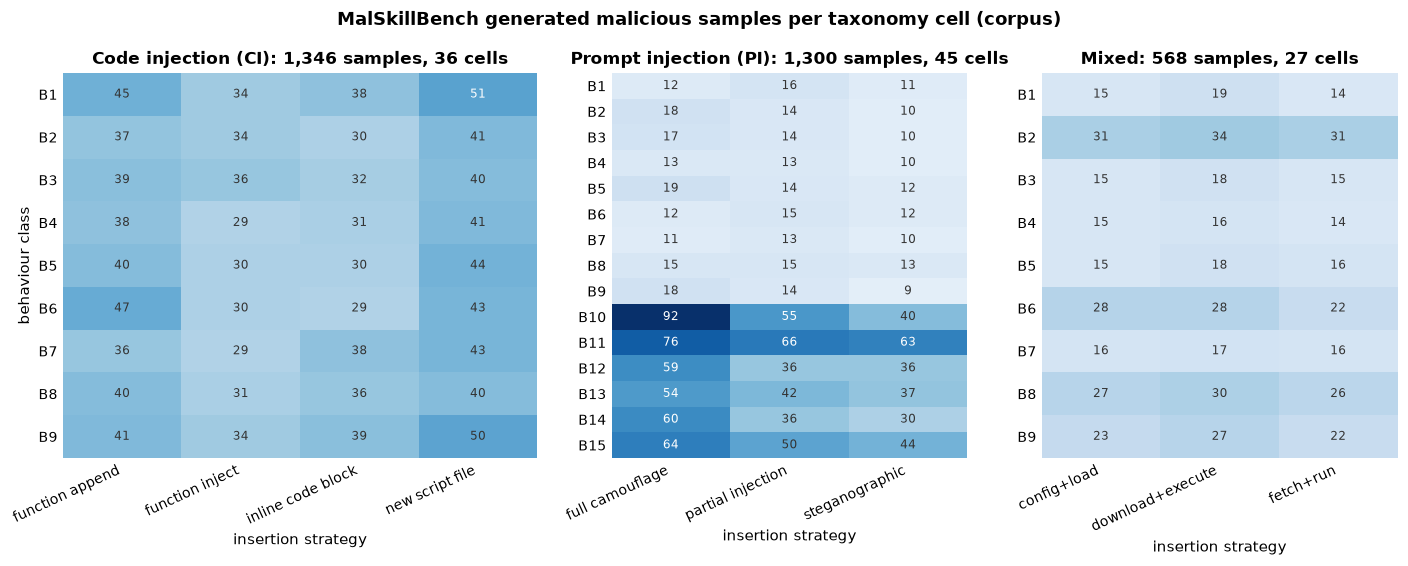

In [4]:
tables = {v: pd.crosstab(tax[tax.vector == v]["behaviour"], tax[tax.vector == v]["insertion"])
             .reindex(BEHAVIOURS).dropna(how="all").fillna(0).astype(int) for v in VECTORS}
vmax = max(t.values.max() for t in tables.values())
fig, axes = plt.subplots(1, 3, figsize=(13, 5.2), gridspec_kw={"width_ratios": [t.shape[1] for t in tables.values()]})
names = {"CI": "Code injection (CI)", "PI": "Prompt injection (PI)", "MIXED": "Mixed"}
for ax, v in zip(axes, VECTORS):
    heatmap(ax, tables[v], vmax)
    ax.set_title(f"{names[v]}: {tables[v].values.sum():,} samples, {(tables[v].values > 0).sum()} cells")
    ax.set_xticklabels([c.replace("_", " ") for c in tables[v].columns], rotation=25, ha="right")
    ax.set_xlabel("insertion strategy")
axes[0].set_ylabel("behaviour class")
fig.suptitle("MalSkillBench generated malicious samples per taxonomy cell (corpus)", fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "taxonomy_cells")

**What this shows**

- The corpus is balanced by class: 4,000 benign and 3,944 malicious skills.
- **There are no traces.** The behaviour half of every pair has to be produced by running the skills, which is
  why the sandbox is part of data collection and not an optional extra.
- Only 28.6% of skills ship a `scripts/` folder (14.2% of benign, 43.3% of malicious). The rest are instructions
  only, so whatever they do is done by the agent that reads them.
- Malicious samples: 3,214 generated, 703 collected in the wild, 27 marked TEST (left out of this project).
- The generated samples fill exactly **108 taxonomy cells**, with 9 to 92 samples per cell. Behaviour classes
  B10 to B15 exist only for prompt injection, and they are the densest cells.
- **Data-quality problem:** 888 malicious `SKILL.md` files (22.5%) still contain the generator's
  `=== END ORIGINAL SKILL.md ===` marker, and no benign file does. Anything that reads the file body could
  learn the class from that line alone. `divergence/data/loader.py` strips it before parsing.

## 2. The sampled runs (2,003 skills, one agent run each)

Running all 7,944 skills was not affordable, so a stratified sample was run: about 1,000 malicious
(spread over every taxonomy cell, plus wild samples) and 1,000 benign. Each skill was run once by an
agent inside the sealed sandbox, and the trace was captured.

In [5]:
def frame(path, mode):
    rows = []
    for line in open(path, encoding="utf-8"):
        s = json.loads(line)
        sig = s["signals"]
        rows.append({
            "sample_id": s["sample_id"], "mode": mode,
            "class": "malicious" if s["dataset_label"] else "benign",
            "source": s["source"] or "benign", "vector": s["attack_vector"], "behaviour": s["behaviour_class"],
            "insertion": s["insertion_strategy"], "has_scripts": s["has_scripts"], "group_key": s["group_key"],
            "outcome": s["observed_outcome"], "timed_out": s["timed_out"],
            "description": s["description"], "desc_words": len(s["description"].split()),
            "desc_source": s["metadata"].get("description_source"),
            "n_actions": len(s["trace"]), "trace": s["trace"],
            "reads a sensitive path": bool(sig["sensitive_paths"]),
            "writes a persistence file": bool(sig["persistence_writes"]),
            "contacts an external host": bool(sig["external_contact"]),
            "runs a shipped script": bool(sig["skill_script_execs"]),
        })
    return pd.DataFrame(rows)


agent = frame(SAMPLES_PATH, "agent")
direct = frame(DIRECT_SAMPLES_PATH, "direct")
instructed = frame(INSTRUCTED_SAMPLES_PATH, "instructed")
runs = pd.concat([agent, direct, instructed], ignore_index=True)
MODE_ORDER = ["agent", "direct", "instructed"]

split_of = {r["sample_id"]: r["split"] for r in csv.DictReader(open(SPLIT_ASSIGNMENT_PATH, encoding="utf-8"))}
runs["split"] = runs["sample_id"].map(split_of)
agent, direct, instructed = (runs[runs["mode"] == m] for m in MODE_ORDER)

print(f"{len(agent)} sampled skills, {agent['sample_id'].nunique()} unique ids")
pd.crosstab(agent["class"], agent["source"], margins=True)

2003 sampled skills, 2003 unique ids


source,GENERATED,WILD,benign,All
class,,,,
benign,0,0,1000,1000
malicious,824,179,0,1003
All,824,179,1000,2003


In [6]:
gen = agent[agent["source"] == "GENERATED"]
cells_sample = gen.groupby(["vector", "behaviour", "insertion"]).size()
print(f"taxonomy cells covered by the sample: {len(cells_sample)} of {len(cells_corpus)}; "
      f"runs per cell: min {cells_sample.min()}, median {int(cells_sample.median())}, max {cells_sample.max()}")

cover = pd.DataFrame({"corpus": tax["vector"].value_counts(), "sample": gen["vector"].value_counts()}).reindex(VECTORS)
cover["sampled %"] = (100 * cover["sample"] / cover["corpus"]).round(1)
display(cover)

scripts = pd.crosstab(agent["class"], agent["has_scripts"].map({True: "ships scripts/", False: "instructions only"}), margins=True)
scripts["% instructions only"] = (100 * scripts["instructions only"] / scripts["All"]).round(1)
scripts

taxonomy cells covered by the sample: 108 of 108; runs per cell: min 2, median 8, max 23


,corpus,sample,sampled %
vector,,,
CI,1346,342,25.4
PI,1300,333,25.6
MIXED,568,149,26.2


has_scripts,instructions only,ships scripts/,All,% instructions only
class,,,,
benign,858,142,1000,85.8
malicious,572,431,1003,57.0
All,1430,573,2003,71.4


**What this shows**

- 2,003 skills were run: 1,000 benign, 824 generated malicious and 179 wild malicious.
- The sample covers **all 108 taxonomy cells** (2 to 23 runs per cell, median 8) and takes about a quarter of
  each attack vector (25.4% / 25.6% / 26.2%), so the sample keeps the corpus's vector proportions.
- 71.4% of the sampled skills are instructions only (85.8% of benign, 57.0% of malicious). Only 573 ship
  scripts. This decides which skills can be run in direct mode later (section 4).

## 3. The description side of each pair

The description is the `description:` line of the `SKILL.md` frontmatter: what a user is shown before
installing. It is one half of every (description, behaviour) pair Divergence compares.

,count,mean,std,min,10%,50%,90%,max
class,,,,,,,,
benign,1000.0,29.5,20.1,1.0,9.0,26.0,53.0,148.0
malicious,1003.0,29.2,18.2,0.0,11.0,26.0,53.0,151.0


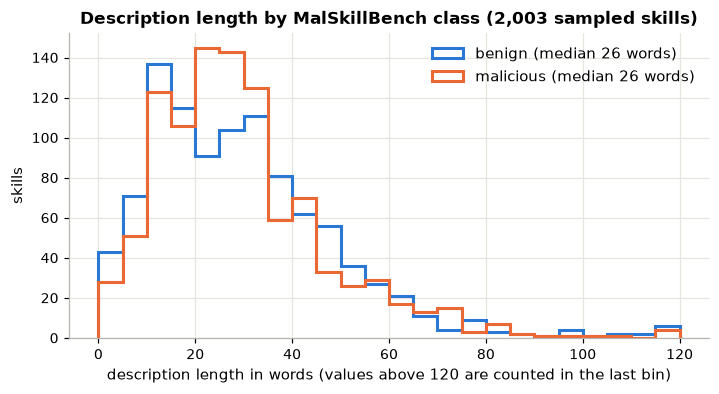

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
bins = np.arange(0, 125, 5)
for cls, colour in zip(("benign", "malicious"), CLASS_COLOURS):
    w = agent.loc[agent["class"] == cls, "desc_words"].clip(upper=120)
    ax.hist(w, bins=bins, histtype="step", linewidth=2, color=colour,
            label=f"{cls} (median {int(agent.loc[agent['class'] == cls, 'desc_words'].median())} words)")
ax.set_xlabel("description length in words (values above 120 are counted in the last bin)")
ax.set_ylabel("skills")
ax.set_title("Description length by MalSkillBench class (2,003 sampled skills)")
ax.legend()
save(fig, "description_length")

agent.groupby("class")["desc_words"].describe(percentiles=[0.1, 0.5, 0.9]).round(1)

In [8]:
print("where the description came from:", dict(agent["desc_source"].value_counts()))
print("skills with no description at all:", int((agent["desc_words"] == 0).sum()))

norm = agent["description"].str.lower().str.split().str.join(" ")
described = agent[norm != ""].assign(norm=norm)
shared = described.groupby("norm").agg(skills=("sample_id", "size"), classes=("class", "nunique"))
dup = shared[shared["skills"] > 1]
print(f"\ndescriptions used by more than one skill: {len(dup)} descriptions, covering {int(dup['skills'].sum())} skills")
print(f"  of these, shared by a benign AND a malicious skill: {int((dup['classes'] == 2).sum())} descriptions, "
      f"{int(dup.loc[dup['classes'] == 2, 'skills'].sum())} skills")
groups = agent.groupby("group_key").size()
print(f"\nskill families (group_key): {len(groups)} for {len(agent)} skills; "
      f"{int((groups > 1).sum())} families have more than one member, the largest has {groups.max()}")

where the description came from: {'frontmatter': np.int64(1944), 'first_paragraph': np.int64(59)}
skills with no description at all: 1

descriptions used by more than one skill: 101 descriptions, covering 311 skills
  of these, shared by a benign AND a malicious skill: 7 descriptions, 14 skills

skill families (group_key): 1820 for 2003 skills; 86 families have more than one member, the largest has 16


**What this shows**

- Benign and malicious descriptions have the same length profile (median 26 words in both classes, 10th to
  90th percentile 9 to 53 and 11 to 53 words). Description length does not give the class away.
- 59 skills had no usable `description:` field, so the first prose paragraph of the body is used instead.
  One skill has no description at all and is excluded from the splits.
- **Near-duplicates are common.** 101 descriptions are shared word for word by 311 skills, 7 of them by a
  benign and a malicious skill. 86 skill families have more than one member (the largest has 16), because
  the generator makes several malicious variants of one base skill.
- **Consequence:** a random split would put near-identical pairs on both sides of the train/test line. The
  split therefore has to keep each family, and each identical description, in one split (section 8).

## 4. What actually happened in the runs

A MalSkillBench "malicious" label says what the skill *is*. Whether the harmful behaviour shows up in
the trace depends on what happened in the run. `observed_outcome` is a rule-based bucket per run
(`divergence/data/outcome.py`). It is a review aid, not ground truth: the hand review in section 7 sets
the final labels.

Three execution modes were used:

| Mode | Runs | Who runs the skill | Why it exists |
|---|---|---|---|
| **agent** | 2,003 | an LLM agent (DeepSeek V4.1 Flash) given a normal task | the realistic case |
| **direct** | 573 | nobody: the skill's own scripts are executed under `strace` | the agent refused most malicious skills, so their payload never ran |
| **instructed** | 361 | a low-refusal agent told to follow the `SKILL.md` | payloads written as prose instructions need an agent to carry them out |

In [9]:
pd.crosstab(runs["mode"], runs["class"], margins=True).reindex(MODE_ORDER + ["All"])

class,benign,malicious,All
mode,,,
agent,1000,1003,2003
direct,159,414,573
instructed,0,361,361
All,1159,1778,2937


agent mode, counts:


class,benign,malicious,All
outcome,,,
All,1000,1003,2003
declined_security,20,739,759
risky_actions_no_skill_code,369,55,424
commands_only,239,130,369
blocked_env,157,46,203
ran_skill_code,183,16,199
error_or_hang,25,8,33
read_only,7,9,16


instructed mode (malicious skills only), counts:


outcome,commands_only,risky_actions_no_skill_code,read_only,ran_skill_code,declined_security,blocked_env
runs,157,83,67,45,7,2


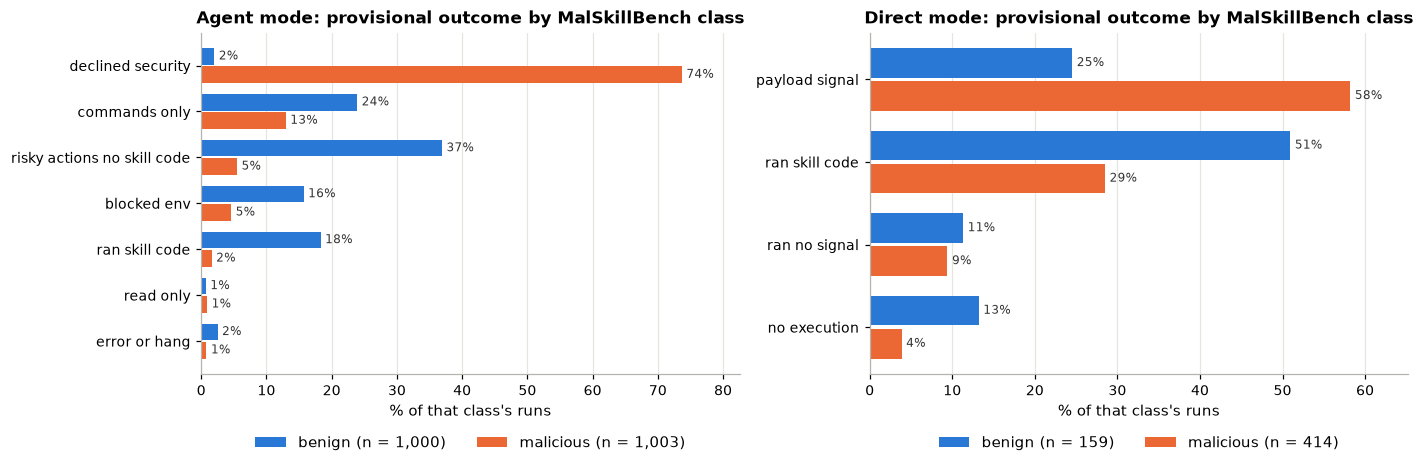

In [10]:
def outcome_share(df):
    t = pd.crosstab(df["outcome"], df["class"], normalize="columns").mul(100)
    return t.reindex(columns=["benign", "malicious"]).sort_values("malicious", ascending=False)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, (name, df) in zip(axes, (("Agent mode", agent), ("Direct mode", direct))):
    t = outcome_share(df)
    t.index = [i.replace("_", " ") for i in t.index]
    n = df["class"].value_counts()
    t.columns = [f"benign (n = {n['benign']:,})", f"malicious (n = {n['malicious']:,})"]
    grouped_barh(ax, t)
    ax.set_xlabel("% of that class's runs")
    ax.set_title(f"{name}: provisional outcome by MalSkillBench class")
    legend_below(ax, y=-0.14)
fig.tight_layout()
save(fig, "outcomes_by_mode")

print("agent mode, counts:")
display(pd.crosstab(agent["outcome"], agent["class"], margins=True).sort_values("All", ascending=False))
print("instructed mode (malicious skills only), counts:")
display(instructed["outcome"].value_counts().to_frame("runs").T)

In [11]:
t = pd.crosstab(agent["class"], agent["timed_out"].map({True: "timed out", False: "finished"}), margins=True)
t["% timed out"] = (100 * t["timed out"] / t["All"]).round(1)
display(t)

ran_direct = set(direct.loc[direct["outcome"] == "payload_signal", "sample_id"])
mal_agent = agent[agent["class"] == "malicious"].set_index("sample_id")
hidden = mal_agent.loc[mal_agent.index.isin(ran_direct) & ~mal_agent["outcome"].isin(["ran_skill_code", "risky_actions_no_skill_code"])]
print(f"malicious skills with no payload bucket under the agent but a payload signal when run directly: {len(hidden)} "
      f"({int((hidden['outcome'] == 'declined_security').sum())} of them the agent had declined on security grounds)")

timed_out,finished,timed out,All,% timed out
class,,,,
benign,856,144,1000,14.4
malicious,952,51,1003,5.1
All,1808,195,2003,9.7


malicious skills with no payload bucket under the agent but a payload signal when run directly: 225 (198 of them the agent had declined on security grounds)


**What this shows**

- **The agent refused most malicious skills.** In agent mode 739 of 1,003 malicious runs (74%) ended in a
  security refusal. Only 71 (7%) fall in a bucket where a payload could be in the trace (16 ran skill code,
  55 risky actions). A refused run's trace shows the agent reading files and nothing else.
- **The rule buckets are not labels.** 369 benign agent runs (37%) land in "risky actions", and in direct mode
  25% of benign runs show a "payload signal" against 58% of malicious runs. Touching the network or a
  config file is normal for many honest skills.
- Benign runs time out more often than malicious ones (14.4% against 5.1%), because the agent actually
  attempts the benign task instead of stopping early.
- **Direct mode recovers what the refusals hid.** 225 malicious skills show no payload bucket under the agent
  but a payload signal when their scripts are run directly; the agent had refused 198 of them.
- Instructed mode covers malicious skills whose payload is written as instructions. 128 of its 361 runs
  (35%) reach a payload-type bucket.
- **Consequences:** (1) `dataset_label` cannot be the training target, because most malicious runs contain
  no malicious behaviour; (2) three execution modes are needed to observe the behaviour at all; (3) the
  final label has to come from reading each run (section 7).

## 5. The behaviour side of each pair: the traces

A trace is an ordered list of normalised actions (`divergence/preprocessing/normalise_trace.py`). In
agent modes the agent's tool calls are the backbone and the operating-system events (from `strace`) are
attached to the command that caused them. In direct mode there are no tool calls, only OS events.

,count,mean,std,min,50%,90%,max,empty traces
mode,,,,,,,,
agent,2003.0,36.3,50.1,0.0,20.0,89.0,883.0,31
direct,573.0,11.3,26.5,0.0,8.0,22.0,571.0,37
instructed,361.0,20.5,54.1,1.0,5.0,53.0,812.0,0


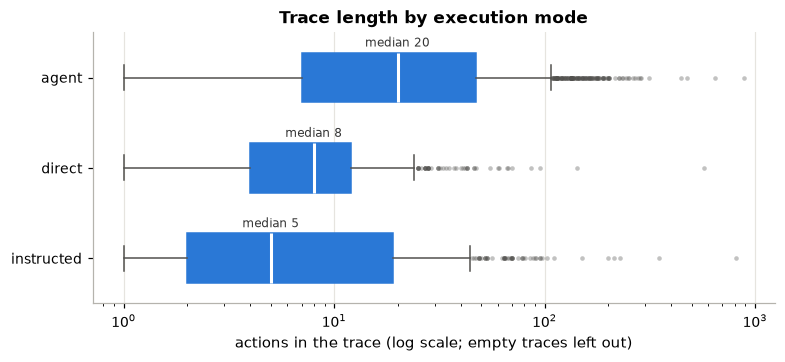

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.2))
data = [runs.loc[(runs["mode"] == m) & (runs["n_actions"] > 0), "n_actions"] for m in MODE_ORDER]
box = ax.boxplot(data, orientation="horizontal", tick_labels=MODE_ORDER, widths=0.55, patch_artist=True,
                 medianprops={"color": "white", "linewidth": 2},
                 flierprops={"marker": "o", "markersize": 3, "markerfacecolor": GREY, "markeredgecolor": "none", "alpha": 0.35},
                 whiskerprops={"color": GREY}, capprops={"color": GREY})
for patch in box["boxes"]:
    patch.set(facecolor=BLUE, edgecolor=BLUE)
for i, d in enumerate(data, start=1):
    ax.text(d.median(), i - 0.31, f"median {int(d.median())}", ha="center", va="bottom", fontsize=8, color="#333333")
ax.set_xscale("log")
ax.set_xlabel("actions in the trace (log scale; empty traces left out)")
ax.set_title("Trace length by execution mode")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
save(fig, "trace_length")

length = runs.groupby("mode")["n_actions"].describe(percentiles=[0.5, 0.9]).reindex(MODE_ORDER).round(1)
length["empty traces"] = runs[runs["n_actions"] == 0].groupby("mode").size().reindex(MODE_ORDER).fillna(0).astype(int)
length

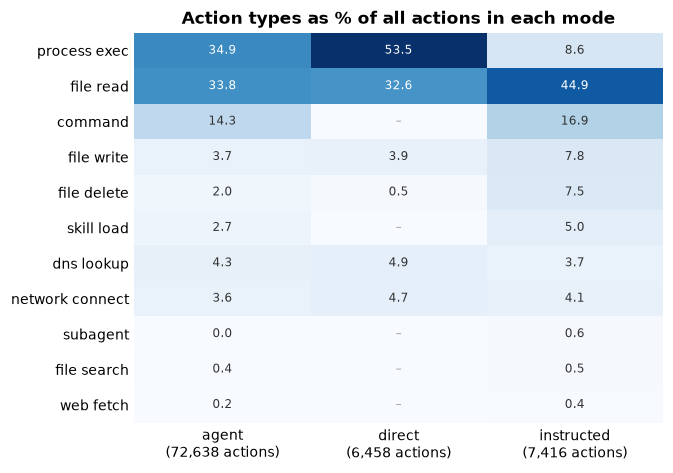

In [13]:
actions = pd.DataFrame([{"mode": m, "action": a["action"]} for m, tr in zip(runs["mode"], runs["trace"]) for a in tr])
mix = pd.crosstab(actions["action"], actions["mode"], normalize="columns").mul(100)[MODE_ORDER]
mix = mix.loc[mix.max(axis=1).sort_values(ascending=False).index]
mix.index = [i.replace("_", " ") for i in mix.index]
mix.columns = [f"{m}\n({(actions['mode'] == m).sum():,} actions)" for m in MODE_ORDER]

fig, ax = plt.subplots(figsize=(6.2, 4.6))
heatmap(ax, mix, vmax=mix.values.max(), fmt="{:.1f}")
ax.set_title("Action types as % of all actions in each mode")
save(fig, "action_mix")

**What this shows**

- Traces are short in the middle and very long in the tail: the median is 20 actions (agent), 8 (direct) and
  5 (instructed), but the longest traces have 883, 571 and 812 actions. A sentence encoder reads a limited
  number of tokens, so a long trace cannot be fed in as it is. This is the reason for the trace-to-text step
  (notebooks 02 and 03 measure the truncation).
- 68 traces are empty (31 agent, 37 direct): the run errored, hung, or nothing executed. An empty trace means
  "nothing observed", not "consistent".
- Process executions and file reads dominate: 69% of agent actions and 86% of direct actions. Network actions
  (DNS lookups and connections) are 8 to 10% of the actions in every mode.
- **The modes look different by construction.** Direct traces have no `command`, `skill load` or other tool
  actions at all, and instructed traces are read-heavy (45% file reads). A model could learn to recognise
  the mode instead of the behaviour, so results must also be reported within each mode.

## 6. Is raw behaviour enough to tell the classes apart?

If malicious skills simply *did* suspicious things and benign ones did not, a rule on behaviour alone
would be enough and there would be nothing for a consistency model to add. Direct mode is the cleanest
place to check, because no agent decides what runs.

*Fine-tune and calibration splits only (see the test-split rule at the top).*

,benign (n = 82),malicious (n = 243)
contacts an external host,30.5,59.7
reads a sensitive path,8.5,26.7
writes a persistence file,1.2,1.6
any of the first three,32.9,60.5
runs a shipped script,75.6,85.6


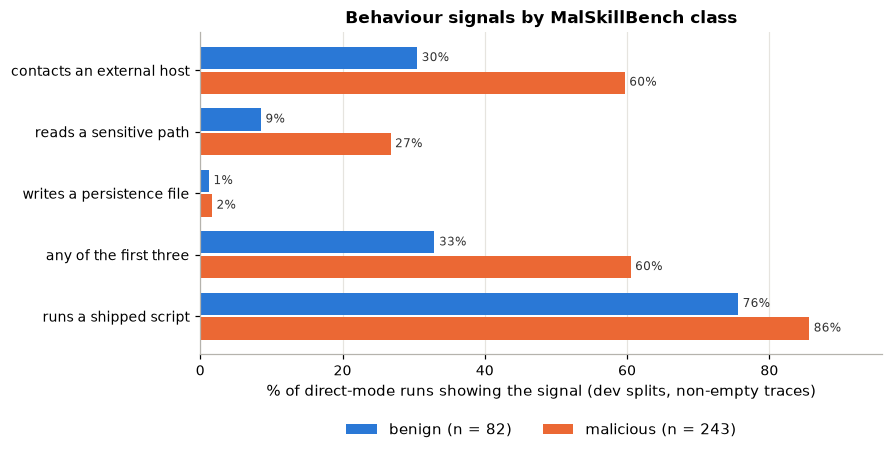

In [14]:
SIGNALS = ["contacts an external host", "reads a sensitive path", "writes a persistence file", "runs a shipped script"]
dev = direct[direct["split"].isin(DEV_SPLITS) & (direct["n_actions"] > 0)]
n = dev["class"].value_counts()
sig = dev.groupby("class")[SIGNALS].mean().mul(100).T[["benign", "malicious"]]
sig.loc["any of the first three"] = dev.groupby("class")[SIGNALS[:3]].apply(lambda d: d.any(axis=1).mean() * 100)
sig = sig.reindex(SIGNALS[:3] + ["any of the first three", SIGNALS[3]])
sig.columns = [f"benign (n = {n['benign']})", f"malicious (n = {n['malicious']})"]

fig, ax = plt.subplots(figsize=(8, 3.8))
grouped_barh(ax, sig)
ax.set_xlabel("% of direct-mode runs showing the signal (dev splits, non-empty traces)")
ax.set_title("Behaviour signals by MalSkillBench class")
legend_below(ax, y=-0.17)
save(fig, "behaviour_signals")
sig.round(1)

**What this shows**

- Suspicious-looking behaviour is more common in malicious skills, but far from exclusive to them: 30% of
  benign direct runs contact an external host (60% of malicious) and 9% read a sensitive path (27%).
- A rule that flags a run when any of the three signals appears would flag a third of the benign runs (33%)
  and still miss about 40% of the malicious ones.
- **Consequence:** behaviour alone does not separate the classes. Whether contacting a host is a problem
  depends on whether the description declares it, which is the comparison Divergence makes. The
  behaviour-only baseline in Experiment 1 tests this directly.

Caveat: this section compares MalSkillBench classes, not hand labels, and direct mode only includes skills
that ship runnable scripts.

## 7. The hand-labelled dataset (308 runs)

The provisional outcomes above are rules. The final target comes from a hand review of each run's
description and trace (`data/processed/review/README.md` has the labelling guide):

- **POS (1)**: a harmful step is in the trace, completed or attempted and stopped by the sandbox.
- **NEG (0)**: the run did what the description declares.
- **excluded**: the trace cannot show the answer (the agent refused, nothing executed, reply-only payload, unsure).

In [15]:
recheck = {(r["mode"], r["sample_id"]): r["recheck_decision"]
           for r in csv.DictReader(open(LABELS_DIR / "review_labels_recheck.csv", encoding="utf-8"))}
reviewed = []
for mode, (labels_path, _, mapping) in MODES.items():
    for r in csv.DictReader(open(labels_path, encoding="utf-8")):
        label = mapping.get(r["reviewed_outcome"])
        if (mode, r["sample_id"]) in recheck:
            label = RECHECK.get(recheck[(mode, r["sample_id"])])
        reviewed.append({"mode": mode, "reviewed_outcome": r["reviewed_outcome"] or "(blank)",
                         "result": {1: "POS", 0: "NEG"}.get(label, "excluded")})
reviewed = pd.DataFrame(reviewed)

funnel = pd.crosstab(reviewed["mode"], reviewed["result"], margins=True).reindex(MODE_ORDER + ["All"])[["POS", "NEG", "excluded", "All"]]
funnel.insert(0, "runs captured", [len(agent), len(direct), len(instructed), len(runs)])
funnel = funnel.rename(columns={"All": "hand-reviewed"})
display(funnel[["runs captured", "hand-reviewed", "POS", "NEG", "excluded"]])

print("why reviewed runs were excluded:")
pd.crosstab(reviewed.loc[reviewed["result"] == "excluded", "reviewed_outcome"],
            reviewed.loc[reviewed["result"] == "excluded", "mode"], margins=True)

result,runs captured,hand-reviewed,POS,NEG,excluded
mode,,,,,
agent,2003,181,5,48,128
direct,573,181,68,67,46
instructed,361,168,76,44,48
All,2937,530,149,159,222


why reviewed runs were excluded:


mode,agent,direct,instructed,All
reviewed_outcome,,,,
(blank),0,0,1,1
blocked_env,51,0,0,51
declined_security,66,0,0,66
error,5,0,0,5
no_execution,0,24,0,24
partial_blocked,0,0,2,2
payload_attempted,2,0,0,2
payload_in_reply_only,4,0,0,4
refused_or_unavailable,0,0,38,38


308 labelled runs from 301 skills: 149 POS / 159 NEG


hand label,NEG (consistent),POS (inconsistent),All
reviewed_outcome,,,
inspected_only,6,0,6
partial_blocked,0,129,129
payload_attempted,0,5,5
payload_confirmed,0,15,15
payload_incidental,73,0,73
ran_clean,38,0,38
task_attempted,42,0,42
All,159,149,308


hand label,NEG (consistent),POS (inconsistent),All
attack_vector,,,
(benign),53,0,53
(wild),21,28,49
CI,35,52,87
MIXED,16,23,39
PI,34,46,80
All,159,149,308


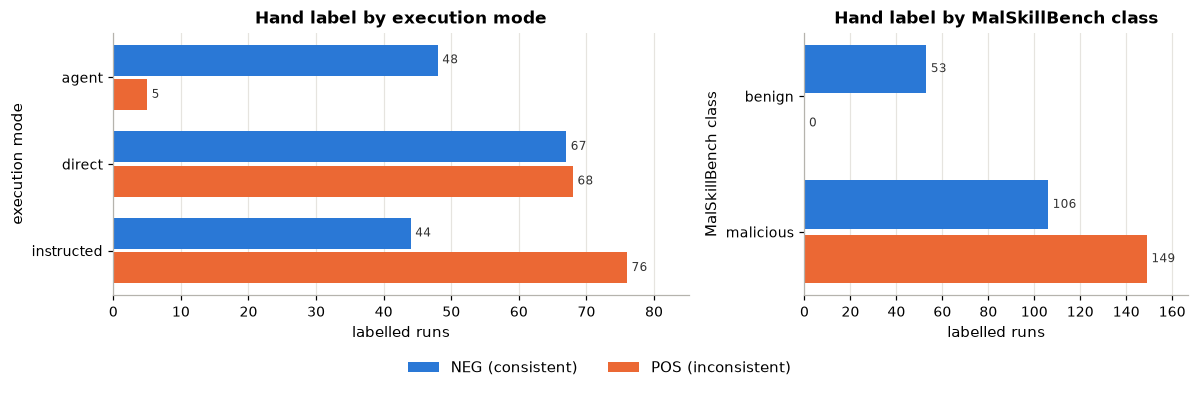

In [16]:
lab = pd.DataFrame([{k: v for k, v in r.items() if k != "trace"} | {"n_actions": len(r["trace"])}
                    for r in load_labelled_dataset()])
lab["hand label"] = lab["label"].map({0: "NEG (consistent)", 1: "POS (inconsistent)"})
lab["class"] = lab["dataset_label"].map({0: "benign", 1: "malicious"})
print(f"{len(lab)} labelled runs from {lab['sample_id'].nunique()} skills: "
      f"{int(lab['label'].sum())} POS / {int((lab['label'] == 0).sum())} NEG")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), gridspec_kw={"width_ratios": [3, 2]})
by_mode = pd.crosstab(lab["mode"], lab["hand label"]).reindex(MODE_ORDER)
by_class = pd.crosstab(lab["class"], lab["hand label"])
for ax, t, title, ylabel in ((axes[0], by_mode, "Hand label by execution mode", "execution mode"),
                             (axes[1], by_class, "Hand label by MalSkillBench class", "MalSkillBench class")):
    grouped_barh(ax, t, fmt="{:.0f}")
    ax.set_xlabel("labelled runs")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.09))
fig.tight_layout()
save(fig, "hand_labels")

display(pd.crosstab(lab["reviewed_outcome"], lab["hand label"], margins=True))
pd.crosstab(lab["attack_vector"].fillna(lab["class"].map({"benign": "(benign)", "malicious": "(wild)"})), lab["hand label"], margins=True)

**What this shows**

- 530 of the 2,937 captured runs were reviewed by hand, chosen by priority (candidate positives first, then
  the benign runs that tripped a rule; `data/processed/review/README.md`). 222 were excluded because the trace
  cannot show the answer: 66 security refusals, 51 environment blocks, 38 instructed runs that refused or
  were unavailable, 29 unsure, 24 with no execution, and 14 others.
- That leaves **308 labelled runs from 301 skills: 149 POS and 159 NEG** (48.4% positive).
- Agent mode contributes only 5 positives. Almost all positives come from direct (68) and instructed (76)
  mode, which confirms that the extra modes were necessary.
- 129 of the 149 positives are `partial_blocked`: the payload ran and was stopped by the sealed sandbox
  (the network led nowhere). The attempt is in the trace, so it counts as observed divergence.
- **Malicious is not the same as inconsistent.** 106 of the 255 labelled runs of malicious skills (42%) are
  NEG: the payload never fired, or what ran was legitimate for that skill. Using `dataset_label` as the target
  would give 106 of 308 runs (34%) the wrong label.
- **Limitation:** every positive comes from a malicious skill; there is no benign skill with an inconsistent
  run. On this data alone, "inconsistent" and "malicious and active" cannot be told apart. Experiment 5
  builds controls for this (a benign trace under a swapped description, and a malicious trace under a
  description that discloses it).

## 8. The splits

The split was made on the 2,003 sampled skills **before** any hand label existed, grouped so that
related skills stay together (5 folds: 2 fine-tune, 1 calibration, 2 test). Direct and instructed runs
of a skill inherit that skill's split. The split is frozen in `split_assignment.csv`.

In [17]:
assign = pd.read_csv(SPLIT_ASSIGNMENT_PATH)
SPLIT_ORDER = ["finetune", "calibration", "held_out_test"]
print("all sampled skills:")
display(pd.crosstab(assign["split"], assign["stratum"].fillna("(none)"), margins=True).reindex(SPLIT_ORDER + ["excluded_no_description", "All"]))

print("hand-labelled runs:")
t = pd.crosstab(lab["split"], lab["hand label"], margins=True).reindex(SPLIT_ORDER + ["All"])
t["% POS"] = (100 * t["POS (inconsistent)"] / t["All"]).round(1)
display(t)
display(pd.crosstab(lab["split"], lab["mode"], margins=True).reindex(SPLIT_ORDER + ["All"])[MODE_ORDER + ["All"]])

kept = assign[assign["split"].isin(SPLIT_ORDER)]
for key in ("leakage_group", "group_key"):
    spans = kept.groupby(key)["split"].nunique()
    print(f"{key}: {len(spans)} groups, {int((spans > 1).sum())} appear in more than one split")
desc_spans = runs[runs["split"].isin(SPLIT_ORDER) & (runs["description"] != "")].assign(
    norm=lambda d: d["description"].str.lower().str.split().str.join(" ")).groupby("norm")["split"].nunique()
print(f"identical descriptions appearing in more than one split: {int((desc_spans > 1).sum())}")
lab_spans = lab.groupby("group_key")["split"].nunique()
print(f"labelled runs: {len(lab_spans)} skill families, {int((lab_spans > 1).sum())} in more than one split")

all sampled skills:


stratum,(none),benign/plain,benign/scripts,malware/CI,malware/MIXED,malware/PI,malware/WILD,All
split,,,,,,,,
finetune,0,343,57,137,60,134,71,802
calibration,0,172,29,68,29,66,36,400
held_out_test,0,343,56,137,59,133,72,800
excluded_no_description,1,0,0,0,0,0,0,1
All,1,858,142,342,148,333,179,2003


hand-labelled runs:


hand label,NEG (consistent),POS (inconsistent),All,% POS
split,,,,
finetune,67,63,130,48.5
calibration,30,31,61,50.8
held_out_test,62,55,117,47.0
All,159,149,308,48.4


mode,agent,direct,instructed,All
split,,,,
finetune,19,64,47,130
calibration,13,27,21,61
held_out_test,21,44,52,117
All,53,135,120,308


leakage_group: 1773 groups, 0 appear in more than one split
group_key: 1819 groups, 0 appear in more than one split
identical descriptions appearing in more than one split: 0
labelled runs: 280 skill families, 0 in more than one split


**What this shows**

- The 2,003 skills are split 802 / 400 / 800 (fine-tune / calibration / held-out test); the one skill with no
  description is excluded. Every stratum (benign with and without scripts, each attack vector, wild) keeps
  the same 40 / 20 / 40 proportion.
- The labelled runs fall 130 / 61 / 117, and the positive share is close to half in each split
  (48.5%, 50.8%, 47.0%), although the split was made before the labels existed.
- **No leakage:** no skill family, merged leakage group or identical description appears in more than one
  split.
- **Limitations:** the calibration split has only 61 labelled runs, so anything fitted on it is uncertain and
  results need confidence intervals. The mode mix also differs between splits (the test split has 52
  instructed and 44 direct runs; the fine-tune split 47 and 64), because the split was fixed before it was
  known which runs would be labelled.

## 9. What one pair looks like

One consistent and one inconsistent pair from the fine-tune split, direct mode. This is everything the
model is given: the declared description and the trace of what ran.

In [18]:
def show(r, n=8):
    print(f"[{r['mode']}] {r['sample_id']}   hand label = {r['label']} ({r['reviewed_outcome']}),  MalSkillBench class = "
          f"{'malicious' if r['dataset_label'] else 'benign'}")
    print("DESCRIPTION:", r["description"][:300])
    print(f"TRACE (first {min(n, len(r['trace']))} of {len(r['trace'])} actions):")
    for a in r["trace"][:n]:
        print(f"   {a['action']:16} {a['target'][:110]}" + ("" if a["status"] == "ok" else f"  [{a['status']}]"))
    print()


ft = load_labelled_dataset(("finetune",))
show(next(r for r in ft if r["label"] == 0 and r["mode"] == "direct" and r["dataset_label"] == 0))
show(next(r for r in ft if r["label"] == 1 and r["mode"] == "direct"))
show(next(r for r in ft if r["label"] == 0 and r["dataset_label"] == 1 and r["mode"] == "direct"))

[direct] benign/clawdgigs   hand label = 0 (payload_incidental),  MalSkillBench class = benign
DESCRIPTION: Register and manage your AI agent profile on ClawdGigs - the Upwork for AI agents with instant x402 micropayments.
TRACE (first 8 of 46 actions):
   process_exec     ./scripts/profile.sh set --name My Agent --bio I specialize in... --skills coding,writing,analysis
   process_exec     ./scripts/gigs.sh create --title Code Review --price 0.10 --category development
   process_exec     ./scripts/earnings.sh
   process_exec     ./scripts/profile.sh
   process_exec     ./scripts/profile.sh set --name New Name --bio Bio text --skills skill1,skill2 --avatar https://...
   process_exec     ./scripts/gigs.sh list
   process_exec     ./scripts/gigs.sh create --title Gig Title --desc Description --price 0.15 --category development
   process_exec     ./scripts/orders.sh list

[direct] malware/Git Commit Helper__CI_B4   hand label = 1 (partial_blocked),  MalSkillBench class = malicious
DESCR

**Reading the three examples**

1. **Benign, NEG.** The skill says it manages a ClawdGigs profile, and the trace starts with its own profile,
   gig and order scripts. Description and behaviour agree.
2. **Malicious, POS.** The skill says it writes commit messages. The trace reads `~/.netrc` (stored
   credentials) and looks up `cdn.gitops.dev`, neither of which a commit-message helper needs. The
   connection fails only because the sandbox has no real internet.
3. **Malicious, NEG.** MalSkillBench labels this skill malicious, but in this run it only contacted
   `alphafold.ebi.ac.uk`, the service its description names, and the script it then tried to run could not be opened. Nothing
   in the trace contradicts the description, so the run is labelled consistent. This is the case that makes
   `dataset_label` unusable as the target.

## 10. Summary: what the data understanding phase established

| # | Finding | Evidence | What was done about it |
|---|---|---|---|
| 1 | MalSkillBench has skills but no traces | section 1 | Traces captured by running 2,003 sampled skills in a sealed sandbox |
| 2 | The sample is representative of the corpus taxonomy | all 108 cells, about 25% of each vector (section 2) | Results can be broken down by attack vector and behaviour class |
| 3 | 888 malicious files carry a generator marker | section 1 | Stripped in `loader.py`; reported as a dataset-quality finding |
| 4 | Variants of one skill share descriptions | 101 shared descriptions, 86 multi-member families (section 3) | Group-aware split; zero groups cross a split (section 8) |
| 5 | The agent refuses 74% of malicious skills | section 4 | Direct and instructed execution modes added |
| 6 | The dataset class is not the behaviour | 42% of labelled malicious-skill runs are consistent (section 7) | Hand review sets the target: 149 POS / 159 NEG |
| 7 | Behaviour alone does not separate the classes | a third of benign direct runs show a risk signal (section 6) | Behaviour is compared with the description; behaviour-only kept as a baseline |
| 8 | Traces can be hundreds of actions long | section 5 | Trace-to-text conversion with a length budget (notebook 03) |
| 9 | The three modes produce differently shaped traces | section 5 | Results reported within each mode as well as pooled |

**Limitations to carry into the report**

- The labelled set is small (308 runs; 61 in the calibration split).
- Every positive run comes from a malicious skill, so inconsistency and active maliciousness are confounded
  in the raw data (addressed by the Experiment 5 controls).
- Most positives (129 of 149) are payloads that were attempted and blocked by the sandbox, not completed.
- Only behaviour that fires during one trial run is observed.
- The hand review covered 530 runs chosen by priority, not a random sample of all 2,937 runs.